# 1. Understand the data

**The question of the whole project:** *can I trust this delivery, and what should I do if I can't?*

This notebook does not build any model. It checks the data, finds the traps in it, and measures how reliable each
shipping option really is. Everything later depends on the traps being handled here.

Data: `data/DataCoSupplyChainDataset.csv`, about 180,000 order lines from 2015 to 2018.

All the logic lives in `core.py`; this notebook calls it so the steps are short and readable.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import core
from core import DATE, MODE, PROMISE, TARGET, TARGET_DAYS
pd.set_option("display.max_columns", 30)

## 1. Load, and the first trap: damaged dates

The CSV was once saved by Excel. Excel re-read some dates such as `1/12/2018` (12 January) as day/month and rewrote
them as `01-12-2018`, with the *first* number now being the month. Reading with one format fails on a big share of rows.
`core.parse_dates` reads both formats.

In [2]:
raw = pd.read_csv(core.DATA_FILE, encoding="latin-1")      # the file is latin-1, not utf-8
raw.columns = [c.strip() for c in raw.columns]
one_format = pd.to_datetime(raw[DATE], format="%m/%d/%Y %H:%M", errors="coerce")
print(f"rows: {len(raw):,}")
print(f"order dates that fail with one format : {one_format.isna().sum():,} ({one_format.isna().mean():.0%})")
print(f"order dates that fail with parse_dates: {core.parse_dates(raw[DATE]).isna().sum()}")

rows: 180,519
order dates that fail with one format : 71,103 (39%)
order dates that fail with parse_dates: 0


In [3]:
df = core.load_dataco()    # drops personal columns and duplicates, parses dates, sorts by time, adds features
print(raw.shape, "->", df.shape)
print("date range:", df[DATE].min(), "->", df[DATE].max())
df[[DATE, MODE, PROMISE, TARGET_DAYS, TARGET, "Sales", "Order Region"]].head()

(180519, 53) -> (180519, 48)
date range: 2015-01-01 00:00:00 -> 2018-01-31 23:38:00


,order date (DateOrders),Shipping Mode,Days for shipment (scheduled),Days for shipping (real),Late_delivery_risk,Sales,Order Region
0,2015-01-01 00:00:00,Standard Class,4,2,0,299.980011,Central America
1,2015-01-01 00:21:00,Standard Class,4,3,0,199.990005,South America
2,2015-01-01 00:21:00,Standard Class,4,3,0,129.990005,South America
3,2015-01-01 00:21:00,Standard Class,4,3,0,250.000000,South America
4,2015-01-01 01:03:00,Standard Class,4,5,1,49.980000,South America


## 2. The second trap: leakage

`Late_delivery_risk` (our target) is 1 when the order was late. Some columns record what happened *after* the order
shipped. If a model sees them it can read the answer instead of predicting it. Check:

In [4]:
print(pd.crosstab(df["Delivery Status"], df[TARGET]))
print("\nForbidden as features (known only after shipping):", core.LEAKY)
print("Missing values per column (only columns with any):")
miss = df.isna().mean().sort_values(ascending=False)
miss[miss > 0].round(3)

Late_delivery_risk      0      1
Delivery Status                 
Advance shipping    41592      0
Late delivery           0  98977
Shipping canceled    7754      0
Shipping on time    32196      0

Forbidden as features (known only after shipping): ['Days for shipping (real)', 'Delivery Status', 'Order Status', 'shipping date (DateOrders)']
Missing values per column (only columns with any):


Series([], dtype: float64)

`Late_delivery_risk` is exactly `Delivery Status == "Late delivery"`. The columns in `core.LEAKY` are never
features, and `core.py` has an `assert` that stops the program if one is added by mistake.

## 3. The third trap: cancelled orders labelled "on time"

Cancelled and suspected-fraud orders never ship, yet DataCo gives them `Late_delivery_risk = 0`. That mixes
"cancelled" into "on time" and makes the payment type TRANSFER, the only type that has them, look reliable.

In [5]:
cancelled = df[df["Delivery Status"] == "Shipping canceled"]
print(f"cancelled orders: {len(cancelled):,}; payment types: {cancelled['Type'].value_counts().to_dict()}")
data = core.shipped_only(df)                      # the population every model and chart uses from now on
by_type = df.groupby("Type")[TARGET].mean().rename("late rate, all orders").to_frame()
by_type["late rate, shipped only"] = data.groupby("Type")[TARGET].mean()
print(f"shipped orders: {len(data):,}   late rate: {data[TARGET].mean():.3f}")
by_type.round(3)

cancelled orders: 7,754; payment types: {'TRANSFER': 7754}
shipped orders: 172,765   late rate: 0.573


,"late rate, all orders","late rate, shipped only"
Type,,
CASH,0.566,0.566
DEBIT,0.572,0.572
PAYMENT,0.575,0.575
TRANSFER,0.485,0.575


## 4. How reliable is each shipping option?

*Late* means slower than the **promise** made at checkout. So we look at the promise and the reality side by side.
`mean_real_days` and `std_real_days` describe how fast and how steady the delivery really is; `late_rate` (with a 95%
interval) says how often the promise is broken.

In [6]:
sc = core.scorecard(data)
sc

,orders,promised_days,mean_real_days,std_real_days,late_rate,late_low,late_high,profit_per_order
Shipping Mode,,,,,,,,
Standard Class,103153,4.0,3.994,1.419,0.398,0.395,0.401,22.033
Same Day,9293,0.0,0.479,0.500,0.479,0.469,0.489,20.896
Second Class,33806,2.0,3.993,1.414,0.798,0.794,0.803,21.383
First Class,26513,1.0,2.000,0.000,1.000,1.000,1.000,23.256


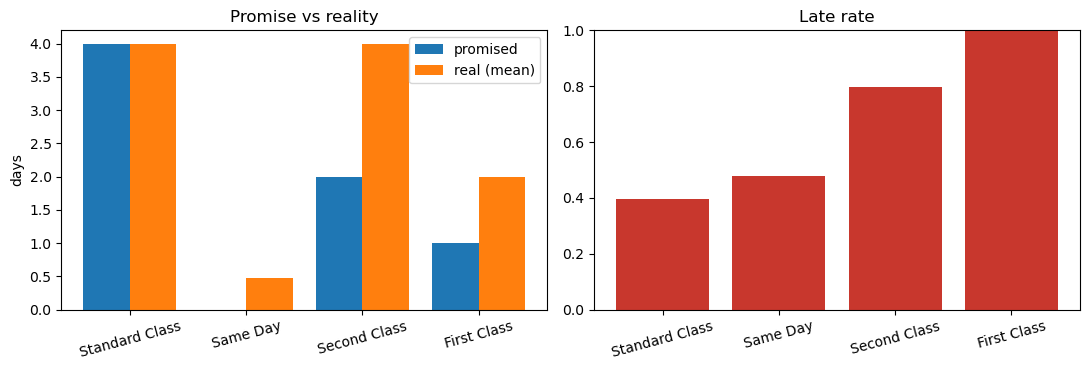

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(sc)); ax[0].bar(x - .2, sc["promised_days"], .4, label="promised"); ax[0].bar(x + .2, sc["mean_real_days"], .4, label="real (mean)")
ax[0].set_xticks(x); ax[0].set_xticklabels(sc.index, rotation=15); ax[0].set_ylabel("days"); ax[0].legend(); ax[0].set_title("Promise vs reality")
ax[1].bar(sc.index, sc["late_rate"], color="#C8372D"); ax[1].set_title("Late rate"); ax[1].set_ylim(0, 1); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

Now the full picture: on which real day does each option arrive? (`Same Day` is split at the noon order cut-off.)

In [8]:
dist = core.real_days_distribution(data)     # rows: option, columns: real days 0..6
print("share of orders delivered on each real day:")
display(dist.round(2))
sd = data[data[MODE] == "Same Day"]
print("Same Day late rate, ordered before / from noon:",
      sd.groupby(sd["order_hour"] >= 12)[TARGET].mean().round(3).to_dict())

share of orders delivered on each real day:


Days for shipping (real),0,1,2,3,4,5,6
option,,,,,,,
First Class,0.0,0.0,1.0,0.0,0.0,0.0,0.0
Same Day (before noon),1.0,0.0,0.0,0.0,0.0,0.0,0.0
Same Day (from noon),0.0,1.0,0.0,0.0,0.0,0.0,0.0
Second Class,0.0,0.0,0.2,0.2,0.2,0.2,0.2
Standard Class,0.0,0.0,0.2,0.2,0.2,0.2,0.2


Same Day late rate, ordered before / from noon: {False: 0.0, True: 1.0}


**What this shows (check it against your output):**

- **Second Class** takes about as long as **Standard Class** (about 4 days, spread over 2 to 6) but *promises* 2 days
  instead of 4. It is late much more often only because its promise is short.
- **First Class** always takes exactly 2 days against a 1-day promise, so it is always late.
- **Same Day** arrives the same day if ordered before noon and the next day if ordered from noon (late).

Lateness in this dataset is therefore set by the promise and one cut-off, not by slow or unreliable delivery.

## 5. Do regions differ? (Be careful: this is where people fool themselves)

A region that uses more Second Class looks unreliable only because of that short promise. So compare each region's
late rate with the rate *its shipping-mode mix alone would give*. `z` measures the gap in standard errors.

In [9]:
reg = core.mode_mix_gap(data, "Order Region")
reg = reg[reg["orders"] >= 1000].sort_values("gap")
n_out = int((reg["z"].abs() > 1.96).sum())
print(f"{n_out} of {len(reg)} regions have |z| > 1.96; about {0.05 * len(reg):.1f} are expected by chance alone")
reg.round(3)

3 of 21 regions have |z| > 1.96; about 1.1 are expected by chance alone


,Order Region,orders,observed,expected,gap,z
19,West Africa,3571,0.547,0.559,-0.013,-1.707
18,US Center,5653,0.575,0.586,-0.011,-1.887
1,Caribbean,7951,0.555,0.566,-0.011,-2.155
10,Northern Europe,9408,0.562,0.569,-0.007,-1.489
8,Eastern Europe,3785,0.576,0.582,-0.005,-0.785
17,Southern Europe,9030,0.568,0.572,-0.004,-0.957
20,West Asia,5746,0.578,0.582,-0.003,-0.605
21,West of USA,7595,0.568,0.570,-0.002,-0.348
3,Central America,27174,0.571,0.572,-0.001,-0.327
9,North Africa,3086,0.571,0.571,-0.000,-0.042


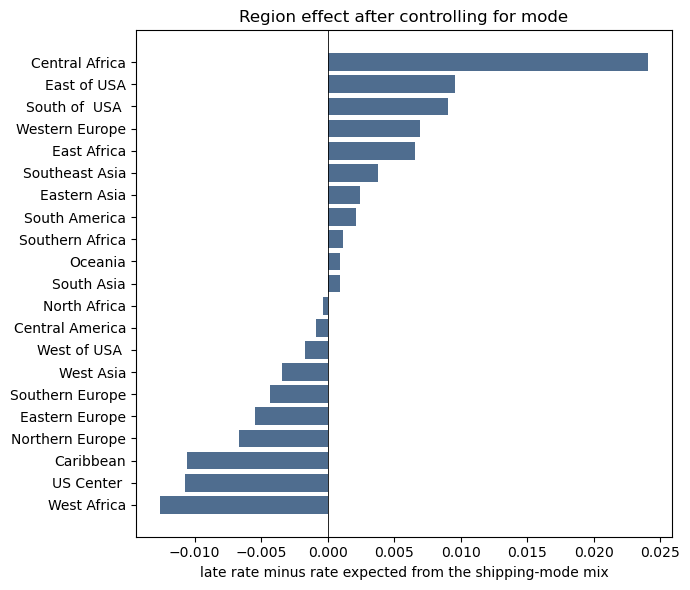

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(reg["Order Region"], reg["gap"], color="#4F6D8F"); ax.axvline(0, color="k", lw=.6)
ax.set(xlabel="late rate minus rate expected from the shipping-mode mix", title="Region effect after controlling for mode")
plt.tight_layout(); plt.show()

## 6. Is the model going to have anything to learn?

The target is set by the promise and the noon cut-off; the rest is random. That predicts a ceiling on how well any
model can do (notebook 2 measures it). Remember the three traps found above: damaged dates, leaky columns,
cancelled orders. Each of them would have produced wrong conclusions without being noticed.

## Findings (fill in from your own output)

1. Damaged dates: 
2. Leakage columns: 
3. Cancelled orders: 
4. Second Class vs Standard Class: 
5. First Class and Same Day: 
6. Regions: 